# Building an ordered hierarchy from asset distances

Correlation is converted into a distance so that strongly positively related assets are close:

$$
d_{ij}=\sqrt{\frac{1-\rho_{ij}}{2}},
\qquad 0\leq d_{ij}\leq1.
$$

Here, $d_{ij}$ is the distance between assets $i$ and $j$, $\rho_{ij}$ is their correlation, and the bounds follow when the correlation lies between minus one and one.

Row,Field,Value
,String,String
1,Archive,49_Industry_Portfolios_daily_CSV.zip
2,Provider,Kenneth R. French Data Library
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Complete dates,1760
7,Selected industries,16


Row,Asset 1,Asset 2,Correlation,Distance
,String,String,Float64,Float64
1,Food,Beer,0.806419,0.311112
2,Soda,Beer,0.787213,0.32618
3,Beer,Hshld,0.776844,0.334033
4,Food,Hshld,0.760632,0.345954
5,Hlth,MedEq,0.751082,0.352788
6,Books,Chems,0.730735,0.366923
7,Soda,Hshld,0.728639,0.368348
8,Food,Soda,0.72426,0.371308
9,Chems,Rubbr,0.723364,0.371911


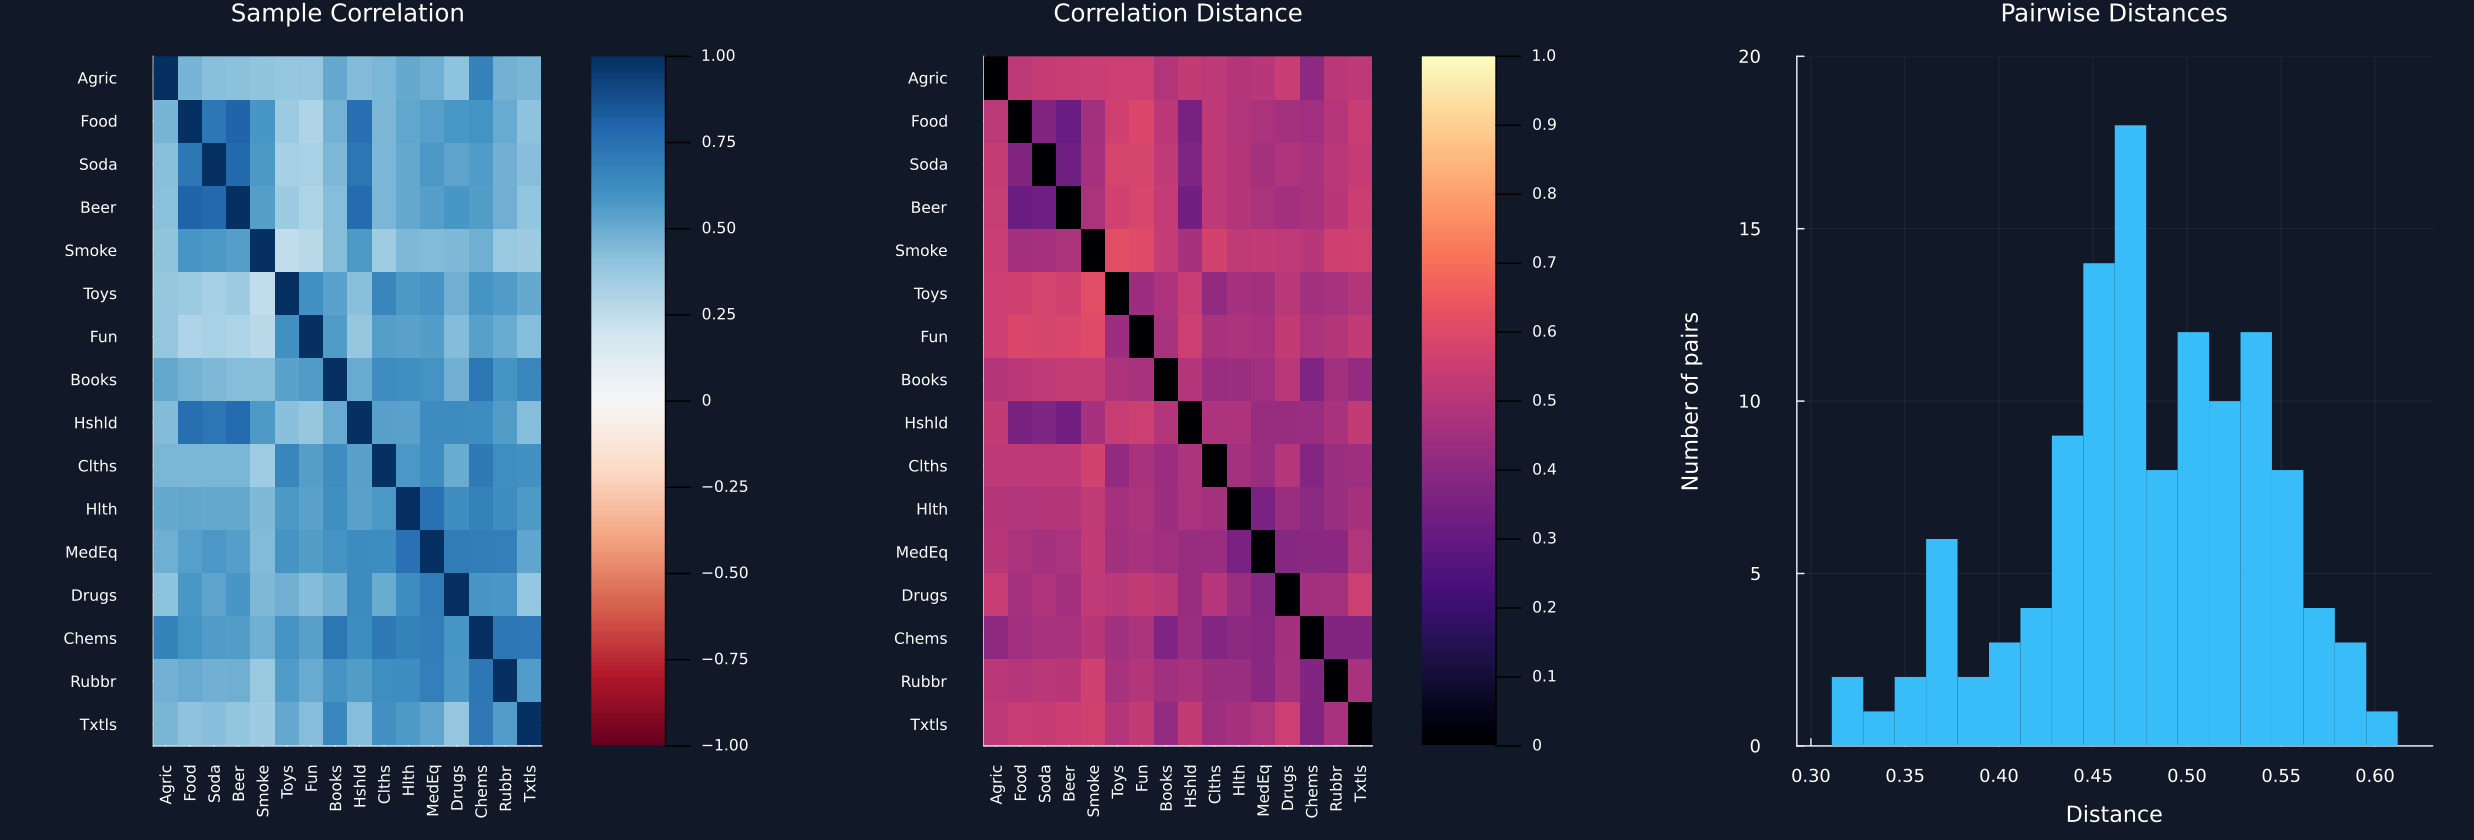

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("25_hierarchical_risk_parity");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
function matrix_panel(values,labels,title;limits=nothing,color=:magma)
    n = length(labels)
    return heatmap(1:n,1:n,values;title,color,clims=isnothing(limits) ? extrema(values) : limits,yflip=true,xticks=(1:n,labels),yticks=(1:n,labels),xrotation=90,tickfontsize=7,xlims=(0.5,n+0.5),ylims=(0.5,n+0.5),widen=false)
end
function tree_panel(tree,order,labels,title)
    n = length(labels)
    positions,heights = zeros(2n-1),zeros(2n-1)
    positions[order] = 1:n
    figure = plot(;title,xlim=(0.3,n+0.7),ylim=(0,1.08*maximum(tree[:,3])),xticks=(1:n,labels[order]),xrotation=90,tickfontsize=7,ylabel="Merge distance",legend=false)
    for step in axes(tree,1)
        left,right = Int.(tree[step,1:2]).+1
        height = tree[step,3]
        plot!(figure,[positions[left],positions[left],positions[right],positions[right]],[heights[left],height,height,heights[right]];color=palette.cyan)
        positions[n+step],heights[n+step] = (positions[left]+positions[right])/2,height
    end
    return figure
end
path_length(distance,order) = sum(distance[order[i],order[i+1]] for i in 1:length(order)-1)
turnover(a,b) = 0.5*sum(abs,a-b)
finite_mean(values) = mean(filter(isfinite,values))
provenance = DataFrame("Field"=>["Archive","Provider","Return type","Analysis start","Analysis end","Complete dates","Selected industries"],"Value"=>["49_Industry_Portfolios_daily_CSV.zip","Kenneth R. French Data Library","Daily value-weighted return",string(first(dates)),string(last(dates)),string(length(dates)),string(length(selected_assets))])
table(provenance,"distance_data_provenance","Public data used for the Chapter 21 hierarchy study.")
distance_values,_,_ = hierarchy(public_correlation)
pair_rows = [(a=selected_assets[i],b=selected_assets[j],correlation=public_correlation[i,j],distance=distance_values[i,j]) for i in 1:15 for j in i+1:16]
pairs = DataFrame(pair_rows)
rename!(pairs,["Asset 1","Asset 2","Correlation","Distance"])
closest_pairs = first(sort(pairs,"Distance"),12)
table(closest_pairs,"closest_distance_pairs","Closest public industry pairs under correlation distance.")
save_data(pairs,paths,"all_distance_pairs")
save_data(matrix_data(public_correlation),paths,"public_correlation")
save_data(matrix_data(distance_values),paths,"public_distances")
p1 = matrix_panel(public_correlation,selected_assets,"Sample Correlation";limits=(-1,1),color=:RdBu)
p2 = matrix_panel(distance_values,selected_assets,"Correlation Distance";limits=(0,1))
p3 = histogram(pairs.Distance;bins=range(extrema(pairs.Distance)...;length=19),color=palette.cyan,linealpha=0,legend=false,title="Pairwise Distances",xlabel="Distance",ylabel="Number of pairs",ylims=(0,20))
save_figure(plot(p1,p2,p3;layout=(1,3),size=(1650,560)),paths,"correlation_distance_matrices")


## Linkage Rules

A linkage rule turns distances between individual assets into a distance between two clusters:

$$
D_{\min}(A,B)=\min_{i\in A,\,j\in B}d_{ij},
\qquad
D_{\max}(A,B)=\max_{i\in A,\,j\in B}d_{ij},
\qquad
D_{\mathrm{avg}}(A,B)=\frac{1}{|A||B|}\sum_{i\in A}\sum_{j\in B}d_{ij}.
$$

Here, $A$ and $B$ are two clusters, $i$ and $j$ label assets, $d_{ij}$ is their correlation distance, $D_{\min}$ is single linkage, $D_{\max}$ is complete linkage, $D_{\mathrm{avg}}$ is average linkage, and $|A|$ and $|B|$ are cluster sizes.

Row,Linkage,Cophenetic correlation,First merge height,Final merge height,Adjacent path length,Mean adjacent correlation
,String,Float64,Float64,Float64,Float64,Float64
1,Single,0.737289,0.311112,0.45442,6.80602,0.573482
2,Complete,0.732651,0.311112,0.612073,6.26477,0.643193
3,Average,0.779075,0.311112,0.516116,6.44909,0.620755


Row,Linkage,Position,Industry
,String,Int64,String
1,Single,1,Smoke
2,Single,2,Fun
3,Single,3,Hshld
4,Single,4,Soda
5,Single,5,Food
6,Single,6,Beer
7,Single,7,Toys
8,Single,8,Agric
9,Single,9,Clths


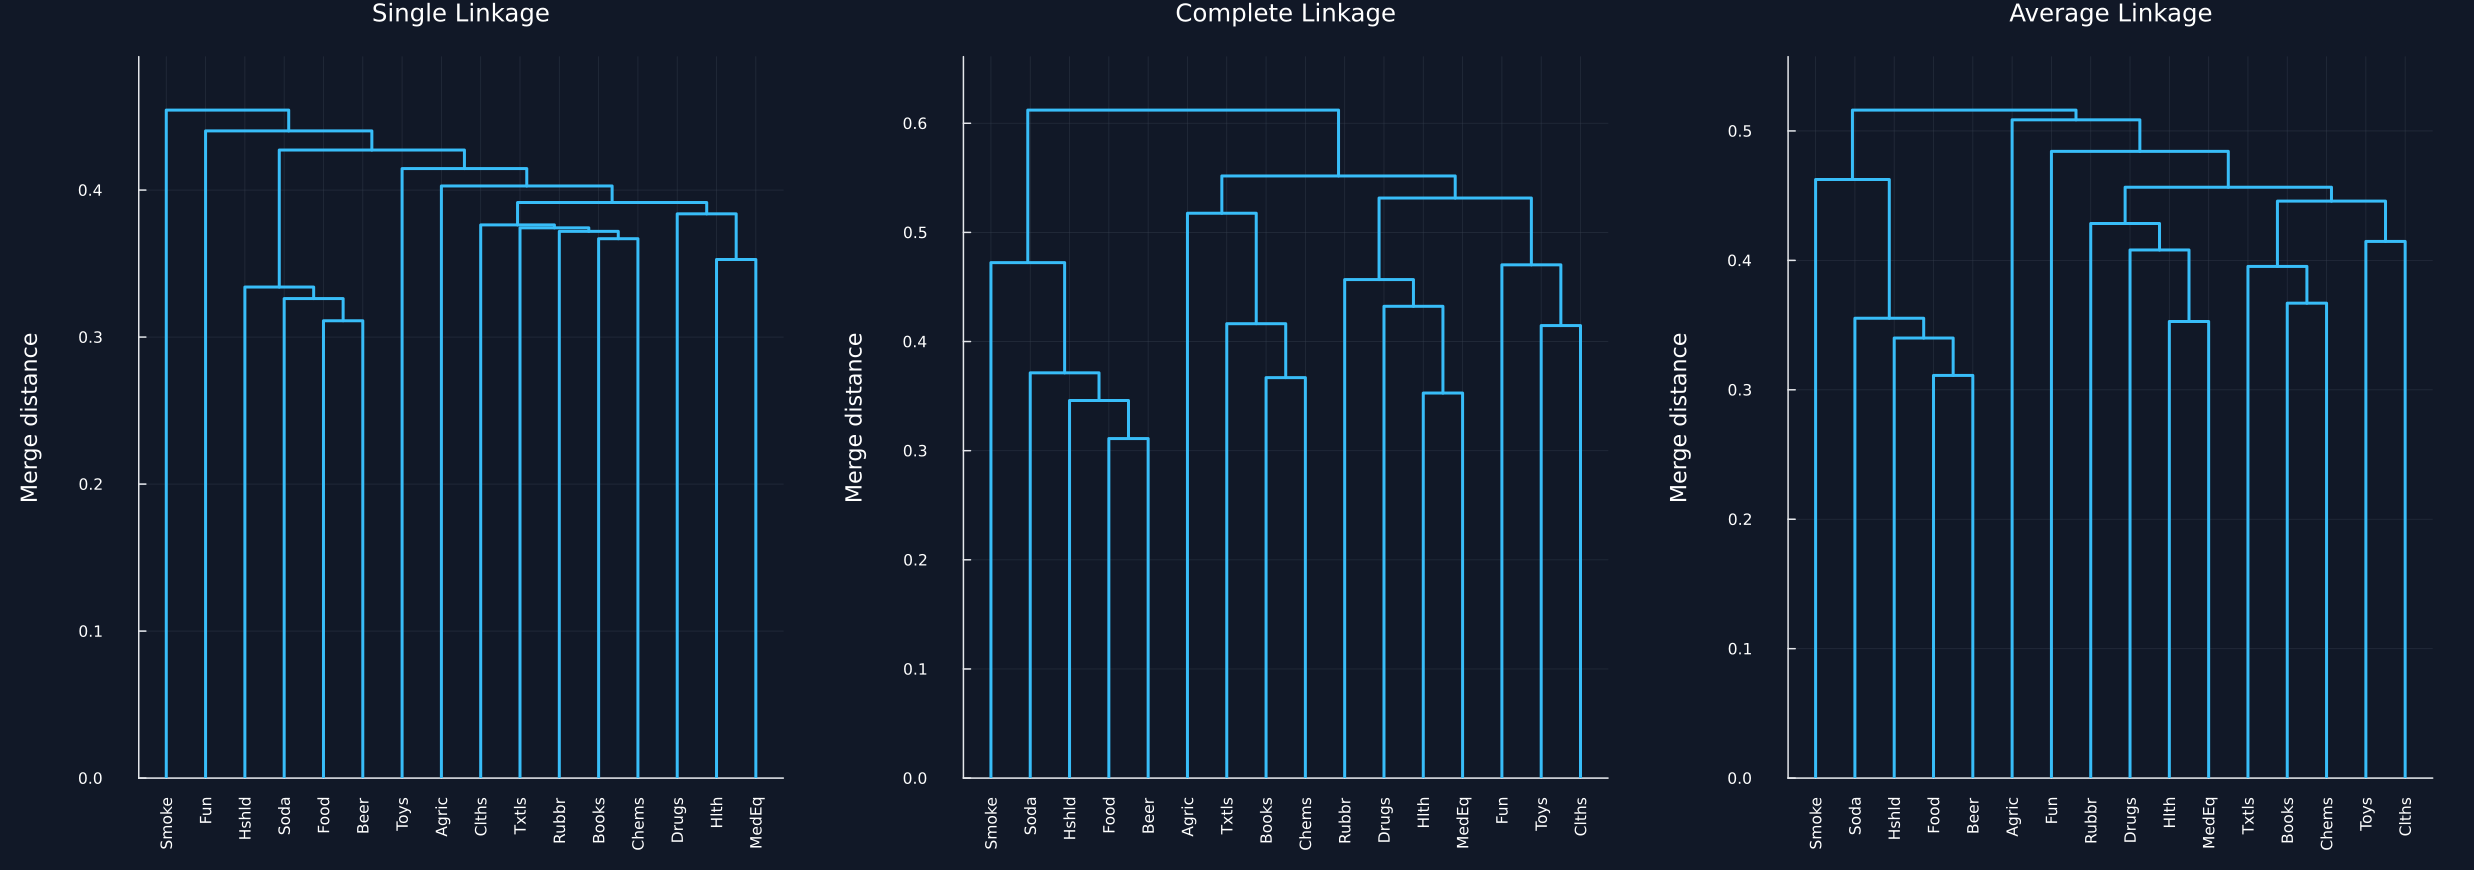

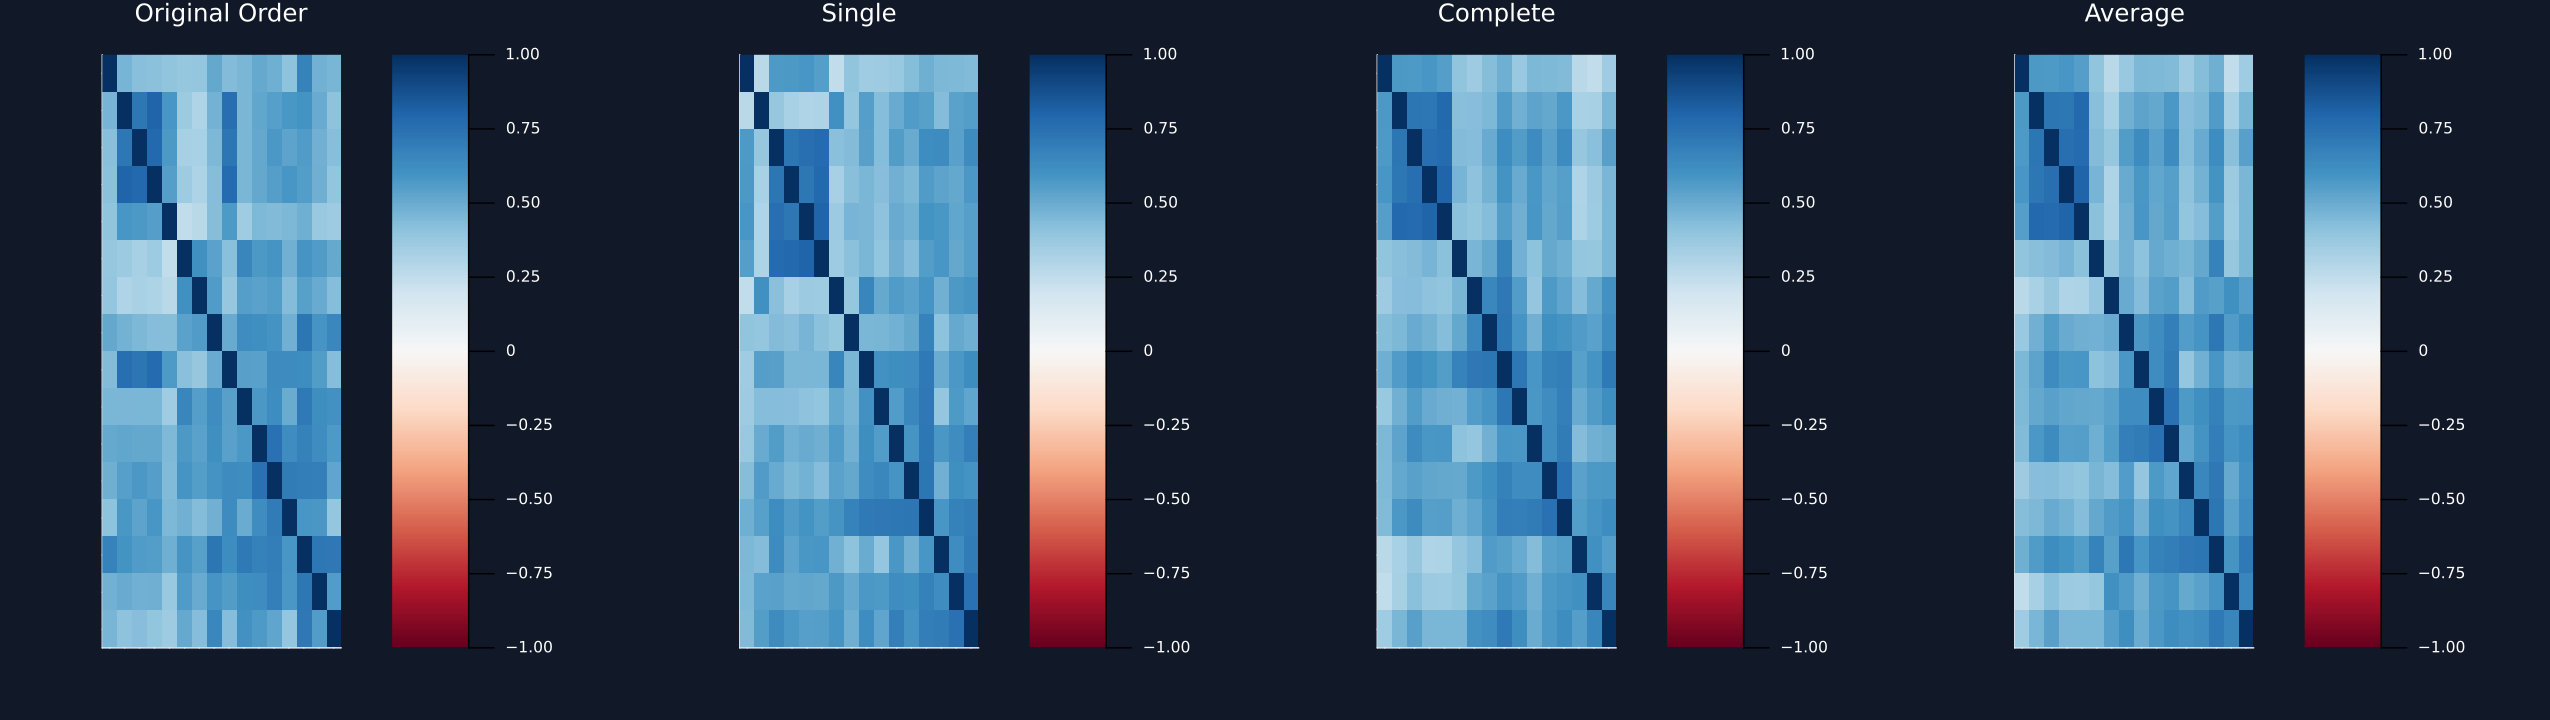

In [2]:
linkage_methods = ["single","complete","average"]
hierarchy_results = Dict(method=>hierarchy(public_correlation,method) for method in linkage_methods)
linkage_rows,order_rows = NamedTuple[],NamedTuple[]
for method in linkage_methods
    distance,tree,order = hierarchy_results[method]
    push!(linkage_rows,(Linkage=titlecase(method),cophenetic=cophenetic_correlation(tree,distance),first=tree[1,3],last=tree[end,3],path=path_length(distance,order),neighbor=mean([public_correlation[order[i],order[i+1]] for i in 1:15])))
    append!(order_rows,[(Linkage=titlecase(method),Position=i,Industry=selected_assets[order[i]]) for i in 1:16])
    save_data(DataFrame(tree,["left","right","height","count"]),paths,"public_tree_"*method)
end
linkage_summary,order_comparison = DataFrame(linkage_rows),DataFrame(order_rows)
rename!(linkage_summary,["Linkage","Cophenetic correlation","First merge height","Final merge height","Adjacent path length","Mean adjacent correlation"])
table(linkage_summary,"linkage_summary","Hierarchy summaries for three linkage rules.")
table(order_comparison,"linkage_orders","Quasi-diagonal industry orders under three linkage rules.")
panels = [tree_panel(hierarchy_results[method][2],hierarchy_results[method][3],selected_assets,titlecase(method)*" Linkage") for method in linkage_methods]
save_figure(plot(panels...;layout=(1,3),size=(1650,580)),paths,"linkage_dendrograms")
panels = [matrix_panel(public_correlation,fill("",16),"Original Order";limits=(-1,1),color=:RdBu)]
for method in linkage_methods
    order = hierarchy_results[method][3]
    push!(panels,matrix_panel(public_correlation[order,order],fill("",16),titlecase(method);limits=(-1,1),color=:RdBu))
end
save_figure(plot(panels...;layout=(1,4),size=(1700,480)),paths,"ordered_correlation_comparison")


## Ordering Diagnostics

One useful diagnostic adds the distances between neighbors in an ordered asset list:

$$
L(\pi)=\sum_{k=1}^{N-1}d_{\pi_k,\pi_{k+1}}.
$$

Here, $\pi=(\pi_1,\ldots,\pi_N)$ is an asset ordering, $N$ is the number of assets, $d_{\pi_k,\pi_{k+1}}$ is the distance between adjacent ordered assets, and $L(\pi)$ is an adjacency diagnostic rather than the rule used to fit the hierarchy.

Row,Window end,Linkage,Observations,Four-cluster agreement with prior window,Adjacent path length,Cophenetic correlation
,String,String,Int64,Float64,Float64,Float64
1,2019-12-31,Single,252,NaN,7.34923,0.824838
2,2019-12-31,Complete,252,NaN,7.38559,0.832963
3,2019-12-31,Average,252,NaN,7.30993,0.849422
4,2020-07-01,Single,252,0.0271132,5.3138,0.751707
5,2020-07-01,Complete,252,-0.015561,4.85311,0.776515
6,2020-07-01,Average,252,-0.015561,4.80942,0.845664
7,2020-12-30,Single,252,1.0,5.00057,0.799081
8,2020-12-30,Complete,252,0.80116,4.90252,0.795782
9,2020-12-30,Average,252,1.0,5.05359,0.865341


Row,Linkage,Mean prior-window agreement,Minimum prior-window agreement,Mean path length,Mean cophenetic correlation
,String,Float64,Float64,Float64,Float64
1,Average,0.644661,-0.015561,6.46699,0.843831
2,Complete,0.597515,-0.015561,6.41583,0.79806
3,Single,0.422813,0.0271132,6.54728,0.793616


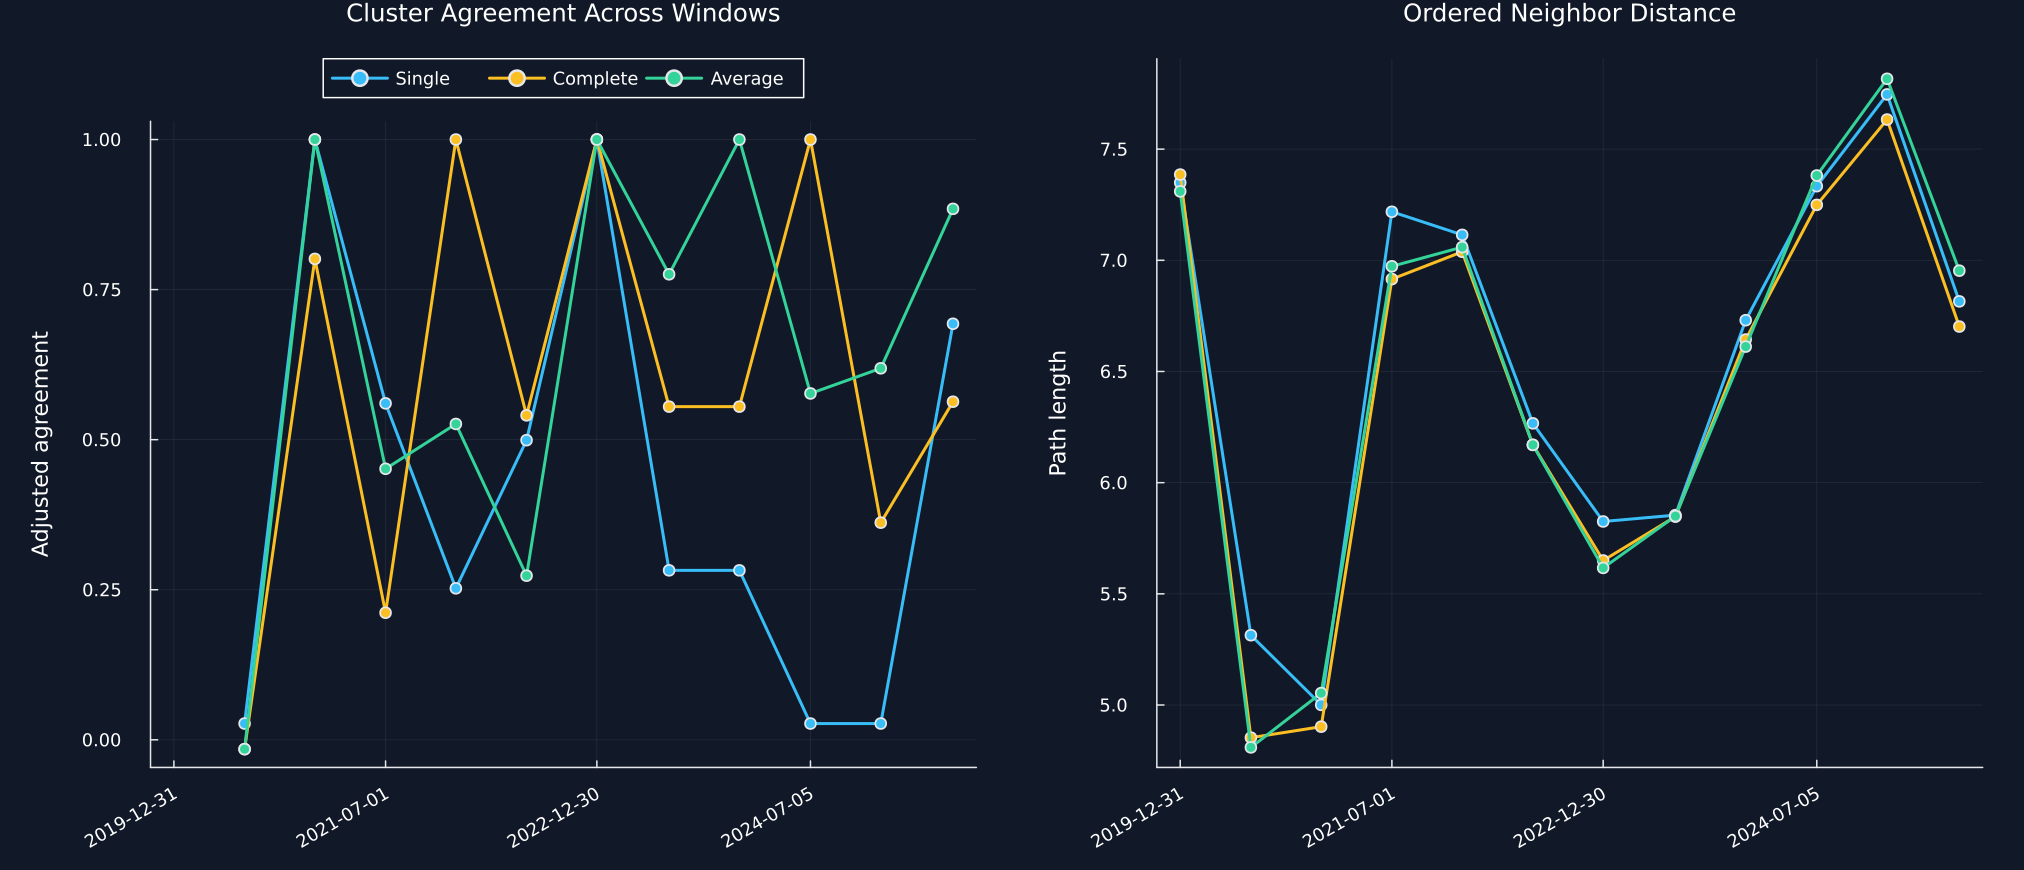

Row,Quantity,Value
,String,Float64
1,Assets,16.0
2,Public observations,1760.0
3,Pairwise distances,120.0
4,Linkage rules,3.0
5,Rolling windows,12.0
6,Smallest observed distance,0.311112
7,Largest observed distance,0.612073


In [3]:
rolling_rows,label_rows = NamedTuple[],NamedTuple[]
previous_labels = Dict{String,Vector{Int}}()
endpoint_positions = collect(252:126:length(dates))
for (window,endpoint) in enumerate(endpoint_positions)
    correlation = cor(public_sample[endpoint-251:endpoint,:])
    for method in linkage_methods
        distance,tree,order = hierarchy(correlation,method)
        labels = max_clusters(tree,4)
        agreement = haskey(previous_labels,method) ? adjusted_agreement(previous_labels[method],labels) : NaN
        push!(rolling_rows,(date=string(dates[endpoint]),Linkage=titlecase(method),Observations=252,agreement=agreement,path=path_length(distance,order),cophenetic=cophenetic_correlation(tree,distance)))
        append!(label_rows,[(window=window,method=method,asset=i,cluster=labels[i]) for i in eachindex(labels)])
        previous_labels[method] = labels
    end
end
rolling_tree_stability = DataFrame(rolling_rows)
rename!(rolling_tree_stability,["Window end","Linkage","Observations","Four-cluster agreement with prior window","Adjacent path length","Cophenetic correlation"])
tree_stability_summary = DataFrame([(Linkage=titlecase(method),agreement=finite_mean(rolling_tree_stability[rolling_tree_stability.Linkage.==titlecase(method),4]),minimum=minimum(filter(isfinite,rolling_tree_stability[rolling_tree_stability.Linkage.==titlecase(method),4])),path=mean(rolling_tree_stability[rolling_tree_stability.Linkage.==titlecase(method),5]),cophenetic=mean(rolling_tree_stability[rolling_tree_stability.Linkage.==titlecase(method),6])) for method in sort(linkage_methods)])
rename!(tree_stability_summary,["Linkage","Mean prior-window agreement","Minimum prior-window agreement","Mean path length","Mean cophenetic correlation"])
table(rolling_tree_stability,"rolling_tree_stability","Rolling public hierarchy diagnostics.")
table(tree_stability_summary,"tree_stability_summary","Summary of rolling public hierarchy diagnostics.")
save_data(DataFrame(label_rows),paths,"rolling_cluster_labels")
p1 = plot(;title="Cluster Agreement Across Windows",ylabel="Adjusted agreement",legend=:outertop,legend_columns=3)
p2 = plot(;title="Ordered Neighbor Distance",ylabel="Path length",legend=false)
tick_indices = 1:3:length(endpoint_positions)
x = Dates.value.(dates[endpoint_positions])
for (method,color) in zip(linkage_methods,[palette.cyan,palette.amber,palette.green])
    subset = rolling_tree_stability[rolling_tree_stability.Linkage.==titlecase(method),:]
    plot!(p1,x,subset[!,4];color,marker=:circle,label=titlecase(method))
    plot!(p2,x,subset[!,5];color,marker=:circle,label=titlecase(method))
end
for panel in [p1,p2]
    plot!(panel;xticks=(x[tick_indices],string.(dates[endpoint_positions[tick_indices]])),xrotation=30)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1350,580)),paths,"window_tree_stability")
section_summary = DataFrame("Quantity"=>["Assets","Public observations","Pairwise distances","Linkage rules","Rolling windows","Smallest observed distance","Largest observed distance"],"Value"=>[16,length(dates),nrow(pairs),3,length(endpoint_positions),minimum(pairs.Distance),maximum(pairs.Distance)])
table(section_summary,"distance_section_summary","Section 21.1 numerical summary.")


## Tests

In [4]:
@assert size(public_sample)==(1760,16)
@assert distance_values≈distance_values'
@assert all(iszero,diag(distance_values))
@assert minimum(distance_values)>=0
@assert maximum(distance_values)<=1
@assert nrow(pairs)==120
@assert sort(pairs.Distance)==sort([distance_values[i,j] for i in 1:15 for j in i+1:16])
@assert issorted(closest_pairs.Distance)
@assert length(hierarchy_results)==3
@assert all(sort(result[3])==collect(1:16) for result in values(hierarchy_results))
@assert all(size(result[2])==(15,4) for result in values(hierarchy_results))
@assert all(0 .<=linkage_summary[!,2].<=1)
@assert all(linkage_summary[!,4].>linkage_summary[!,3])
@assert all(length(unique(group.Industry))==16 for group in groupby(order_comparison,:Linkage))
@assert all(rolling_tree_stability.Observations.==252)
@assert all(-1 .<=filter(isfinite,rolling_tree_stability[!,4]).<=1)
@assert nrow(tree_stability_summary)==3
@assert isfile(joinpath(paths.figures,"correlation_distance_matrices.pdf"))
@assert isfile(joinpath(paths.figures,"linkage_dendrograms.pdf"))
@assert isfile(joinpath(paths.figures,"ordered_correlation_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"window_tree_stability.pdf"))
@assert isfile(joinpath(paths.tables,"linkage_summary.tex"))
@assert isfile(joinpath(paths.tables,"rolling_tree_stability.tex"))
